In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
PROJECT_ROOT = Path.cwd().parent

IMAGE_DIR = PROJECT_ROOT / "data" / "raw" / "images"

METADATA_FILE = (
    PROJECT_ROOT / "data" / "raw" / "metadata" / "FabricNet_parameters.xlsx"
)

print("Project root:", PROJECT_ROOT)
print("Image directory exists:", IMAGE_DIR.exists())
print("Metadata file exists:", METADATA_FILE.exists())

Project root: d:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L
Image directory exists: True
Metadata file exists: True


Load metadata

In [4]:
df = pd.read_excel(METADATA_FILE)

print("Metadata loaded successfully!")
print("Number of records:", len(df))

df.head()

Metadata loaded successfully!
Number of records: 130


,Image id,Specific Mass,Warp,Weft,Texture
0,1,140,32,30,twill
1,2,140,32,30,twill
2,3,140,32,30,twill
3,4,140,32,30,twill
4,5,140,32,30,twill


Check the metadata

In [5]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (130, 5)

Column names:
['Image id', 'Specific Mass', 'Warp', 'Weft', 'Texture']

Data types:
Image id         int64
Specific Mass    int64
Warp             int64
Weft             int64
Texture            str
dtype: object

Missing values:
Image id         0
Specific Mass    0
Warp             0
Weft             0
Texture          0
dtype: int64


Count the images

In [6]:
image_files = list(IMAGE_DIR.glob("*.jpg"))

print("Total image files:", len(image_files))

Total image files: 130


Check the number of images in each class

In [7]:
class_counts = df["Texture"].value_counts()

print("Number of images in each class:")
print(class_counts)

Number of images in each class:
Texture
plain    50
satin    41
twill    39
Name: count, dtype: int64


visualise the distribution:

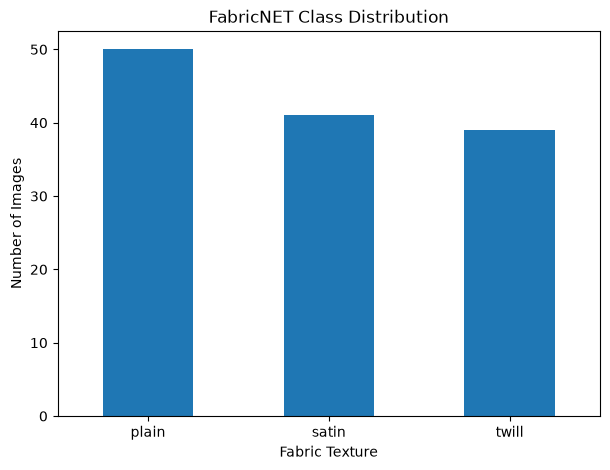

In [8]:
plt.figure(figsize=(7, 5))

class_counts.plot(kind="bar")

plt.title("FabricNET Class Distribution")
plt.xlabel("Fabric Texture")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)

plt.show()

Check unique metadata combinations

In [9]:
metadata_columns = [
    "Specific Mass",
    "Warp",
    "Weft",
    "Texture"
]

unique_combinations = df[metadata_columns].drop_duplicates()

print("Total records:", len(df))
print("Unique metadata combinations:", len(unique_combinations))

Total records: 130
Unique metadata combinations: 29


Display a sample fabric image

Image size: (640, 480)
Image format: JPEG


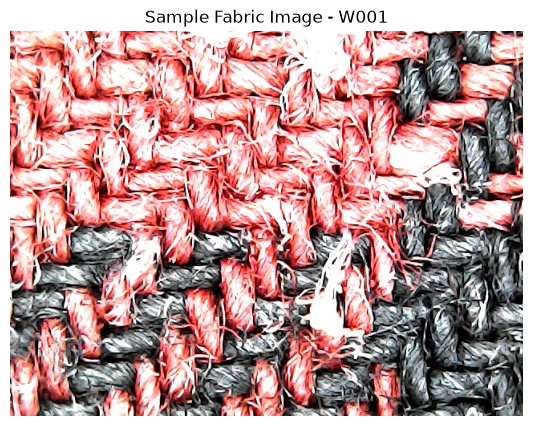

In [10]:
sample_image_path = IMAGE_DIR / "W001.jpg"

image = Image.open(sample_image_path)

print("Image size:", image.size)
print("Image format:", image.format)

plt.figure(figsize=(7, 5))
plt.imshow(image)
plt.title("Sample Fabric Image - W001")
plt.axis("off")
plt.show()

Check whether all metadata IDs are unique

In [11]:
print("Total metadata records:", len(df))

print("Unique image IDs:", df["Image id"].nunique())

print("Duplicate image IDs:", df["Image id"].duplicated().sum())

print("Minimum image ID:", df["Image id"].min())

print("Maximum image ID:", df["Image id"].max())

Total metadata records: 130
Unique image IDs: 130
Duplicate image IDs: 0
Minimum image ID: 1
Maximum image ID: 130


Match Excel IDs with image filenames

In [12]:
# Generate the expected filename for each metadata record
df["image_filename"] = df["Image id"].apply(
    lambda image_id: f"W{int(image_id):03d}.jpg"
)

# Check whether each expected image exists
df["image_path"] = df["image_filename"].apply(
    lambda filename: IMAGE_DIR / filename
)

df["image_exists"] = df["image_path"].apply(
    lambda path: path.exists()
)

print("Images found:", df["image_exists"].sum())
print("Images missing:", (~df["image_exists"]).sum())

df[["Image id", "image_filename", "Texture", "image_exists"]].head(10)

Images found: 130
Images missing: 0


,Image id,image_filename,Texture,image_exists
0,1,W001.jpg,twill,True
1,2,W002.jpg,twill,True
2,3,W003.jpg,twill,True
3,4,W004.jpg,twill,True
4,5,W005.jpg,twill,True
5,6,W006.jpg,twill,True
6,7,W007.jpg,twill,True
7,8,W008.jpg,twill,True
8,9,W009.jpg,twill,True
9,10,W010.jpg,twill,True


Check all image dimensions

In [13]:
from collections import Counter

image_dimensions = []

for image_path in IMAGE_DIR.glob("*.jpg"):
    with Image.open(image_path) as img:
        image_dimensions.append(img.size)

dimension_counts = Counter(image_dimensions)

print("Image dimension distribution:")

for dimensions, count in dimension_counts.items():
    print(dimensions, ":", count)

Image dimension distribution:
(640, 480) : 130


Check for corrupted images

In [14]:
corrupted_images = []

for image_path in IMAGE_DIR.glob("*.jpg"):
    try:
        with Image.open(image_path) as img:
            img.verify()
    except Exception:
        corrupted_images.append(image_path.name)

print("Corrupted images:", len(corrupted_images))
print(corrupted_images)

Corrupted images: 0
[]


Check metadata group sizes

In [15]:
metadata_columns = ["Specific Mass", "Warp", "Weft", "Texture"]

group_sizes = (
    df.groupby(metadata_columns)
    .size()
    .reset_index(name="image_count")
    .sort_values("image_count", ascending=False)
)

print("Number of unique metadata combinations:", len(group_sizes))

print("\nImages per metadata combination:")
print(group_sizes.to_string(index=False))

print("\nDistribution of group sizes:")
print(group_sizes["image_count"].value_counts().sort_index())

Number of unique metadata combinations: 29

Images per metadata combination:
 Specific Mass  Warp  Weft Texture  image_count
           130    56    30   twill            6
           240    30    50   satin            6
            95    30    15   plain            5
           105    38    33   plain            5
           100    24    48   plain            5
           105    44    35   twill            5
           105    62    30   plain            5
           110    26    23   plain            5
           120    62    35   satin            5
           135    44    35   twill            5
           140    32    30   twill            5
           142    22    44   satin            5
            85    32    23   plain            5
           150    24    18   plain            5
           150    26    18   plain            5
           150    30    45   satin            5
           150    26    25   twill            5
           175    22    35   plain            5
           

Check how many groups belong to each fabric class

In [16]:
class_group_summary = (
    group_sizes.groupby("Texture")
    .agg(
        number_of_groups=("image_count", "count"),
        total_images=("image_count", "sum"),
        smallest_group=("image_count", "min"),
        largest_group=("image_count", "max")
    )
    .reset_index()
)

print(class_group_summary.to_string(index=False))

Texture  number_of_groups  total_images  smallest_group  largest_group
  plain                10            50               5              5
  satin                 9            41               1              6
  twill                10            39               1              6


Prepare five-fold grouped splitting

In [17]:
from sklearn.model_selection import StratifiedGroupKFold

# Create a group ID from the four metadata attributes
df["group_id"] = (
    df.groupby(metadata_columns, sort=True)
    .ngroup()
)

# Create five grouped and stratified folds
sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Check each fold
for fold, (train_idx, test_idx) in enumerate(
    sgkf.split(
        X=df,
        y=df["Texture"],
        groups=df["group_id"]
    ),
    start=1
):
    train_df = df.iloc[train_idx]
    test_df = df.iloc[test_idx]

    print(f"\nFold {fold}")
    print("Training images:", len(train_df))
    print("Testing images:", len(test_df))

    print("\nTesting class distribution:")
    print(test_df["Texture"].value_counts())

    # Verify that groups do not overlap
    train_groups = set(train_df["group_id"])
    test_groups = set(test_df["group_id"])

    print("Overlapping groups:", len(train_groups & test_groups))


Fold 1
Training images: 103
Testing images: 27

Testing class distribution:
Texture
plain    10
satin    10
twill     7
Name: count, dtype: int64
Overlapping groups: 0

Fold 2
Training images: 107
Testing images: 23

Testing class distribution:
Texture
plain    10
twill     7
satin     6
Name: count, dtype: int64
Overlapping groups: 0

Fold 3
Training images: 100
Testing images: 30

Testing class distribution:
Texture
plain    10
twill    10
satin    10
Name: count, dtype: int64
Overlapping groups: 0

Fold 4
Training images: 104
Testing images: 26

Testing class distribution:
Texture
plain    10
satin     9
twill     7
Name: count, dtype: int64
Overlapping groups: 0

Fold 5
Training images: 106
Testing images: 24

Testing class distribution:
Texture
plain    10
twill     8
satin     6
Name: count, dtype: int64
Overlapping groups: 0


implement 224 × 224 preprocessing!

Original size: (640, 480)
Processed size: (224, 224)


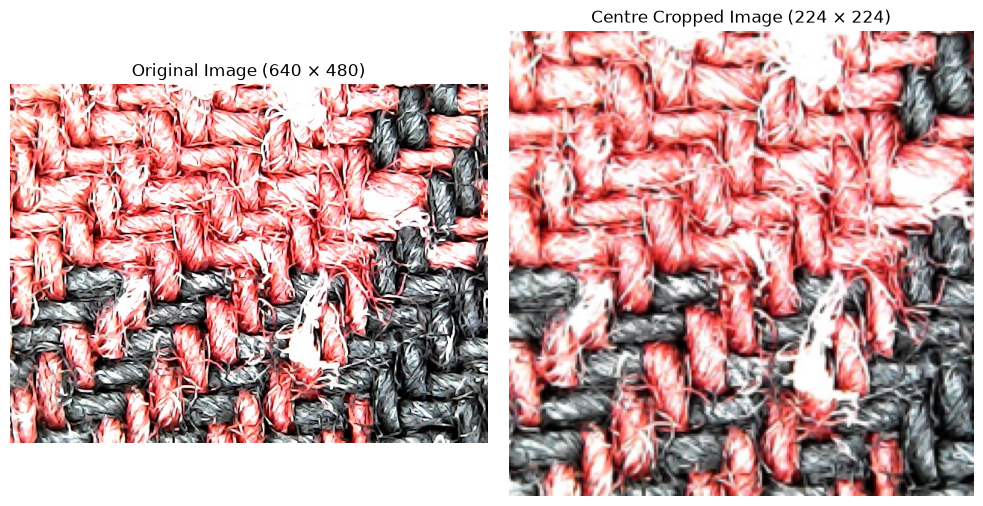

In [18]:
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt

# Define preprocessing
preprocess = transforms.Compose([
    transforms.CenterCrop(480),
    transforms.Resize((224, 224))
])

# Load one original image
image_path = IMAGE_DIR / "W001.jpg"
original_image = Image.open(image_path).convert("RGB")

# Apply preprocessing
processed_image = preprocess(original_image)

print("Original size:", original_image.size)
print("Processed size:", processed_image.size)

# Display both images
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(original_image)
axes[0].set_title("Original Image (640 × 480)")
axes[0].axis("off")

axes[1].imshow(processed_image)
axes[1].set_title("Centre Cropped Image (224 × 224)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

Prepare images for ResNet-18

So far, we have resized the image to 224 × 224. However, ResNet-18 also expects the image to be converted into a PyTorch tensor and normalized.

ToTensor() converts the image into a format PyTorch can process.
Normalize() adjusts pixel values using the ImageNet mean and standard deviation because we plan to use a pretrained ResNet-18 model.

Image Tensor Conversion and Normalization

In [19]:
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt

# ImageNet normalization values
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

# Define preprocessing pipeline
preprocess = transforms.Compose([
    transforms.CenterCrop(480),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Load original image
image_path = IMAGE_DIR / "W001.jpg"
original_image = Image.open(image_path).convert("RGB")

# Apply preprocessing
processed_image = preprocess(original_image)

# Check the processed image
print("Original image size:", original_image.size)
print("Processed tensor shape:", processed_image.shape)
print("Tensor data type:", processed_image.dtype)
print("Minimum tensor value:", processed_image.min().item())
print("Maximum tensor value:", processed_image.max().item())

Original image size: (640, 480)
Processed tensor shape: torch.Size([3, 224, 224])
Tensor data type: torch.float32
Minimum tensor value: -2.1179039478302
Maximum tensor value: 2.640000104904175


Create PyTorch Dataset

In [20]:
# Define numerical labels for the three fabric classes

class_to_idx = {
    "plain": 0,
    "satin": 1,
    "twill": 2
}

idx_to_class = {
    value: key for key, value in class_to_idx.items()
}

print("Class to index:", class_to_idx)
print("Index to class:", idx_to_class)

Class to index: {'plain': 0, 'satin': 1, 'twill': 2}
Index to class: {0: 'plain', 1: 'satin', 2: 'twill'}


Create the Dataset class

In [21]:
import torch
from torch.utils.data import Dataset

class FabricDataset(Dataset):

    def __init__(self, dataframe, image_dir, transform=None):

        self.dataframe = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        # Get one row from the metadata
        row = self.dataframe.iloc[index]

        # Get image filename
        image_filename = row["image_filename"]

        # Build image path
        image_path = self.image_dir / image_filename

        # Load image
        image = Image.open(image_path).convert("RGB")

        # Get the correct numerical label
        label = class_to_idx[row["Texture"]]

        # Apply preprocessing
        if self.transform:
            image = self.transform(image)

        return image, label

Test the Dataset class

In [22]:
# Create a dataset using all 130 images
fabric_dataset = FabricDataset(
    dataframe=df,
    image_dir=IMAGE_DIR,
    transform=preprocess
)

# Retrieve the first image
image, label = fabric_dataset[0]

print("Total images:", len(fabric_dataset))
print("Image tensor shape:", image.shape)
print("Image tensor type:", image.dtype)
print("Numerical label:", label)
print("Fabric class:", idx_to_class[label])

Total images: 130
Image tensor shape: torch.Size([3, 224, 224])
Image tensor type: torch.float32
Numerical label: 2
Fabric class: twill


Create a PyTorch DataLoader

In [23]:
from torch.utils.data import DataLoader

# Define batch size
BATCH_SIZE = 16

# Create DataLoader
fabric_loader = DataLoader(
    fabric_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

print("Number of images:", len(fabric_dataset))
print("Batch size:", BATCH_SIZE)
print("Number of batches:", len(fabric_loader))

Number of images: 130
Batch size: 16
Number of batches: 9


Test the DataLoader

In [24]:
# Retrieve one batch
images, labels = next(iter(fabric_loader))

print("Images batch shape:", images.shape)
print("Labels batch shape:", labels.shape)

print("\nLabels in this batch:")
print(labels)

print("\nFabric classes in this batch:")
print([idx_to_class[label.item()] for label in labels])

Images batch shape: torch.Size([16, 3, 224, 224])
Labels batch shape: torch.Size([16])

Labels in this batch:
tensor([2, 2, 1, 0, 0, 0, 1, 2, 0, 2, 1, 2, 0, 2, 0, 0])

Fabric classes in this batch:
['twill', 'twill', 'satin', 'plain', 'plain', 'plain', 'satin', 'twill', 'plain', 'twill', 'satin', 'twill', 'plain', 'twill', 'plain', 'plain']


Step 18.1 – Create the processed data folder

In [25]:
from pathlib import Path

# Find the project folder
current_dir = Path.cwd()

if current_dir.name == "notebooks":
    project_root = current_dir.parent
else:
    project_root = current_dir

# Create the processed data folder
processed_dir = project_root / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

# Save the dataset metadata
metadata_path = processed_dir / "metadata.csv"
df.to_csv(metadata_path, index=False)

print("Metadata saved successfully!")
print("File location:", metadata_path)
print("Number of records:", len(df))

Metadata saved successfully!
File location: d:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\data\processed\metadata.csv
Number of records: 130


Step 18.3 – Generate and save the five-fold assignments

In [26]:
import numpy as np
from sklearn.model_selection import StratifiedGroupKFold

# Create the five-fold splitter
sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Initially, assign -1 to every image
test_fold = np.full(len(df), -1)

# Generate the five folds
for fold, (train_idx, test_idx) in enumerate(
    sgkf.split(
        X=df,
        y=df["Texture"],
        groups=df["group_id"]
    ),
    start=1
):
    test_fold[test_idx] = fold

# Add the fold assignment to the dataframe
df["test_fold"] = test_fold

# Save the fold information
folds_df = df[
    ["image_filename", "Texture", "group_id", "test_fold"]
].copy()

folds_path = processed_dir / "folds.csv"
folds_df.to_csv(folds_path, index=False)

print("Fold assignments saved successfully!")
print("File location:", folds_path)
print("Total images:", len(folds_df))

Fold assignments saved successfully!
File location: d:\MyFiles\Work File\Master's\Sem3\Project\FabricNet-XAI\masters-capstone-ml-project-268468L\data\processed\folds.csv
Total images: 130


Step 18.4 – Verify the saved fold assignments

In [27]:
# Check how many test images belong to each fold
print("Number of test images in each fold:")
print(folds_df["test_fold"].value_counts().sort_index())

# Check class distribution in each test fold
print("\nClass distribution in each test fold:")
print(
    pd.crosstab(
        folds_df["test_fold"],
        folds_df["Texture"]
    )
)

# Check whether any images were not assigned
print("\nUnassigned images:", (folds_df["test_fold"] == -1).sum())

# Check whether all 29 groups are assigned to only one test fold
group_fold_counts = folds_df.groupby("group_id")["test_fold"].nunique()

print(
    "\nGroups assigned to more than one test fold:",
    (group_fold_counts > 1).sum()
)

Number of test images in each fold:
test_fold
1    27
2    23
3    30
4    26
5    24
Name: count, dtype: int64

Class distribution in each test fold:
Texture    plain  satin  twill
test_fold                     
1             10     10      7
2             10      6      7
3             10     10     10
4             10      9      7
5             10      6      8

Unassigned images: 0

Groups assigned to more than one test fold: 0
